In [1]:
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

# the repo root = the first folder above us that has pyproject.toml
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())

con = duckdb.connect(str(ROOT / "data/warehouse.duckdb"), read_only=True)
signals = con.sql("SELECT * FROM mart_weekend_signals WHERE NOT is_wet_race").df()
fp2 = con.sql("""
    SELECT season, round, driver_code, median(gap_to_best_same_tyre_pct) AS fp2_long_run_gap_pct
    FROM mart_long_runs WHERE session_type = 'FP2' GROUP BY ALL
""").df()
signals = signals.merge(fp2, on=["season", "round", "driver_code"], how="left")
signals["weekend"] = signals["season"] * 100 + signals["round"]
signals.shape, signals["weekend"].nunique()


((1846, 17), 96)

Text(0.5, 0.98, 'Bahrain 2024: signal vs race pace')

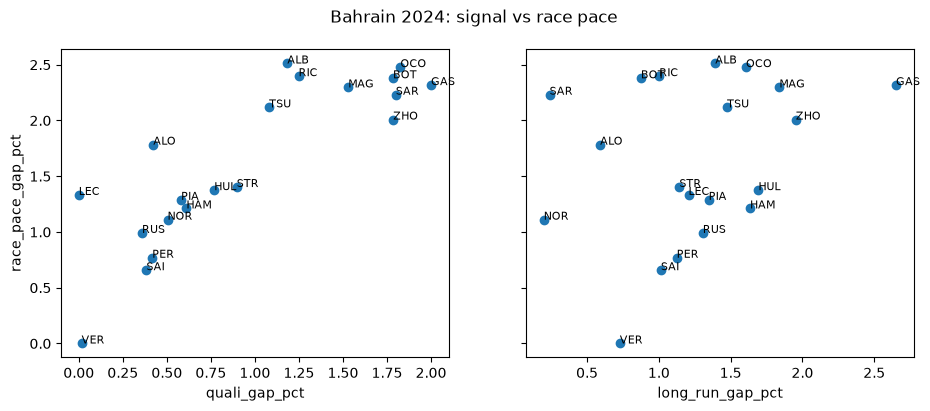

In [2]:
wk = signals[signals["weekend"] == 202401]
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, col in zip(axes, ["quali_gap_pct", "long_run_gap_pct"]):
    ax.scatter(wk[col], wk["race_pace_gap_pct"])
    for _, r in wk.iterrows():
        ax.annotate(r["driver_code"], (r[col], r["race_pace_gap_pct"]), fontsize=8)
    ax.set_xlabel(col)
axes[0].set_ylabel("race_pace_gap_pct")
fig.suptitle("Bahrain 2024: signal vs race pace")

In [3]:
def weekend_correlations(df, signal, min_drivers=8):
    """Spearman correlation between a signal and race pace, one number per weekend."""
    rows = []
    for weekend, g in df.groupby("weekend"):
        g = g.dropna(subset=[signal, "race_pace_gap_pct"])
        if len(g) >= min_drivers:
            rho = g[signal].corr(g["race_pace_gap_pct"], method="spearman")
            rows.append({"weekend": weekend, "season": g["season"].iloc[0], "rho": rho})
    return pd.DataFrame(rows)

both = signals.dropna(subset=["long_run_gap_pct", "quali_gap_pct"])
results = {s: weekend_correlations(both, s) for s in ["quali_gap_pct", "long_run_gap_pct"]}
results["fp2_long_run_gap_pct"] = weekend_correlations(signals, "fp2_long_run_gap_pct")
for name, r in results.items():
    print(f"{name:<22} weekends {len(r):>3}  median rho {r['rho'].median():.2f}  share above 0.5 {(r['rho'] > 0.5).mean():.2f}")

# the fair FP2 comparison (note 2)
fp2_both = signals.dropna(subset=["fp2_long_run_gap_pct", "quali_gap_pct"])
for s in ["quali_gap_pct", "fp2_long_run_gap_pct"]:
    print(s, round(weekend_correlations(fp2_both, s)["rho"].median(), 2))

quali_gap_pct          weekends  86  median rho 0.80  share above 0.5 0.90
long_run_gap_pct       weekends  86  median rho 0.39  share above 0.5 0.31
fp2_long_run_gap_pct   weekends  58  median rho 0.59  share above 0.5 0.60
quali_gap_pct 0.8
fp2_long_run_gap_pct 0.57


In [4]:
diff = results["long_run_gap_pct"]["rho"].values - results["quali_gap_pct"]["rho"].values
rng = np.random.default_rng(0)
boot = [rng.choice(diff, len(diff)).mean() for _ in range(5000)]
print(f"long runs minus quali: {diff.mean():.2f}, 95% CI {np.percentile(boot, [2.5, 97.5]).round(2)}")


long runs minus quali: -0.41, 95% CI [-0.48 -0.34]


In [5]:
def loo_weekend_mae(df, columns):
    """Fit race_pace_gap_pct ~ columns on all weekends but one, predict that one. Mean abs error."""
    X = np.column_stack([np.ones(len(df))] + [df[c].values for c in columns])
    y = df["race_pace_gap_pct"].values
    errors = []
    for w in df["weekend"].unique():
        test = (df["weekend"] == w).values
        coef = np.linalg.lstsq(X[~test], y[~test], rcond=None)[0]
        errors.extend(np.abs(X[test] @ coef - y[test]))
    return np.mean(errors)

print("no signal (just the average):", round(loo_weekend_mae(both, []), 3))
print("qualifying only:              ", round(loo_weekend_mae(both, ["quali_gap_pct"]), 3))
print("long runs only:               ", round(loo_weekend_mae(both, ["long_run_gap_pct"]), 3))
print("qualifying + long runs:       ", round(loo_weekend_mae(both, ["quali_gap_pct", "long_run_gap_pct"]), 3))

no signal (just the average): 0.885
qualifying only:               0.597
long runs only:                0.843
qualifying + long runs:        0.586


In [6]:
by_season = pd.DataFrame({name: r.groupby("season")["rho"].median().round(2) for name, r in results.items()})
by_season

,quali_gap_pct,long_run_gap_pct,fp2_long_run_gap_pct
season,,,
2022,0.74,0.44,0.59
2023,0.66,0.16,0.28
2024,0.83,0.44,0.62
2025,0.75,0.30,0.33
2026,0.92,0.51,0.70


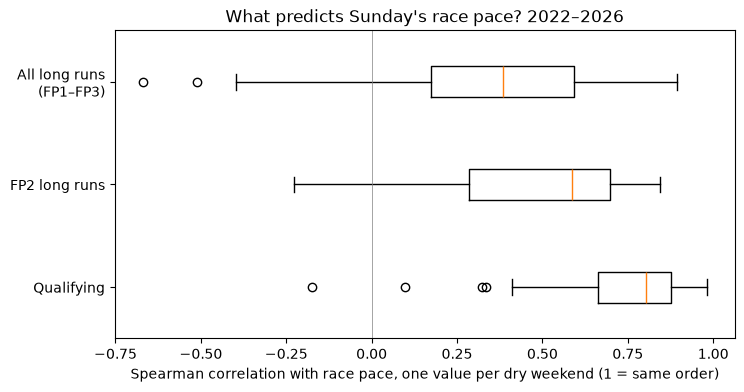

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
names = ["quali_gap_pct", "fp2_long_run_gap_pct", "long_run_gap_pct"]
labels = ["Qualifying", "FP2 long runs", "All long runs\n(FP1–FP3)"]
ax.boxplot([results[n]["rho"] for n in names], tick_labels=labels, orientation="horizontal")
ax.axvline(0, color="grey", lw=0.5)
ax.set_xlabel("Spearman correlation with race pace, one value per dry weekend (1 = same order)")
ax.set_title("What predicts Sunday's race pace? 2022–2026")
fig.savefig(ROOT / "docs/images/practice-vs-race.png", dpi=150, bbox_inches="tight")
